In [11]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
from pathlib import Path

# Load Gapminder dataset
df = px.data.gapminder()

# Create folder to save charts
output_dir = Path("week04_charts")
output_dir.mkdir(parents=True, exist_ok=True)

print("Dataset loaded successfully!")
print("Total rows:", len(df))
print(df.head())


Dataset loaded successfully!
Total rows: 1704
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [12]:
# Dataset information
print(df.info())

# Available years
print("Years:", sorted(df["year"].unique()))

# Available continents
print("Continents:", df["continent"].unique())

# Statistical summary
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    

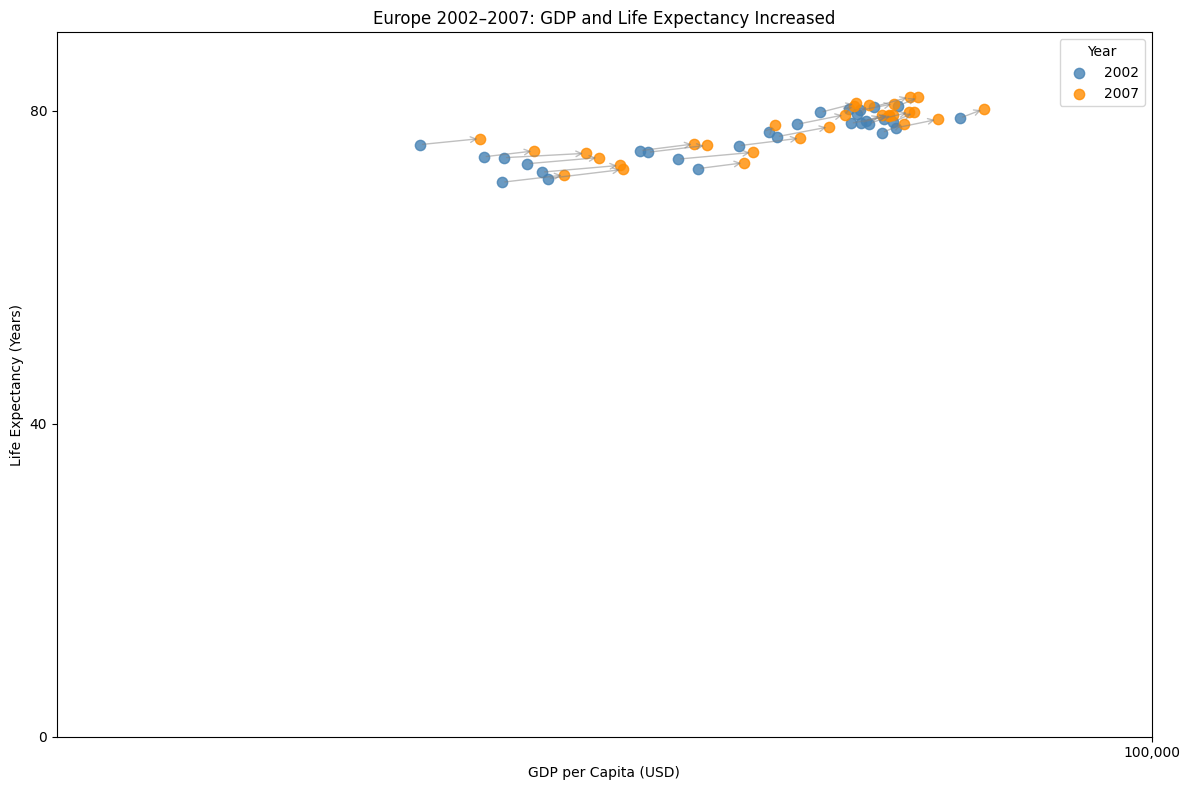

In [23]:
# Filter Europe data for 2002 and 2007
data = df[
    (df["continent"] == "Europe") &
    (df["year"].isin([2002, 2007]))
].copy()

colors = {
    2002: "steelblue",
    2007: "darkorange"
}

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# Plot scatter points
for year in [2002, 2007]:
    part = data[data["year"] == year]

    ax.scatter(
        part["gdpPercap"],
        part["lifeExp"],
        color=colors[year],
        label=str(year),
        s=55,
        alpha=0.8
    )

# Add arrows showing changes
wide = data.pivot(
    index="country",
    columns="year",
    values=["gdpPercap", "lifeExp"]
)

for country, row in wide.iterrows():
    x1 = row[("gdpPercap", 2002)]
    y1 = row[("lifeExp", 2002)]
    x2 = row[("gdpPercap", 2007)]
    y2 = row[("lifeExp", 2007)]

    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            color="gray",
            alpha=0.5
        )
    )

# X-axis: logarithmic scale
ax.set_xscale("log")
ax.set_xlim(1000, 100000)

ax.xaxis.set_major_locator(
    FixedLocator([100000])
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{int(x):,}")
)

ax.xaxis.set_minor_locator(NullLocator())

# Y-axis: start at 0, gap of 5
ax.set_ylim(0, 90)
ax.set_yticks(np.arange(0, 91, 40))

# Labels and title
ax.set_xlabel("GDP per Capita (USD)")
ax.set_ylabel("Life Expectancy (Years)")
ax.set_title(
    "Europe 2002–2007: GDP and Life Expectancy Increased"
)

# Remove background grids
ax.grid(False)

# Legend
ax.legend(title="Year")

# Adjust layout
fig.tight_layout()

# Save charts
fig.savefig(
    output_dir / "task1_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "task1_scatter.pdf",
    bbox_inches="tight"
)

# Display chart
plt.show()


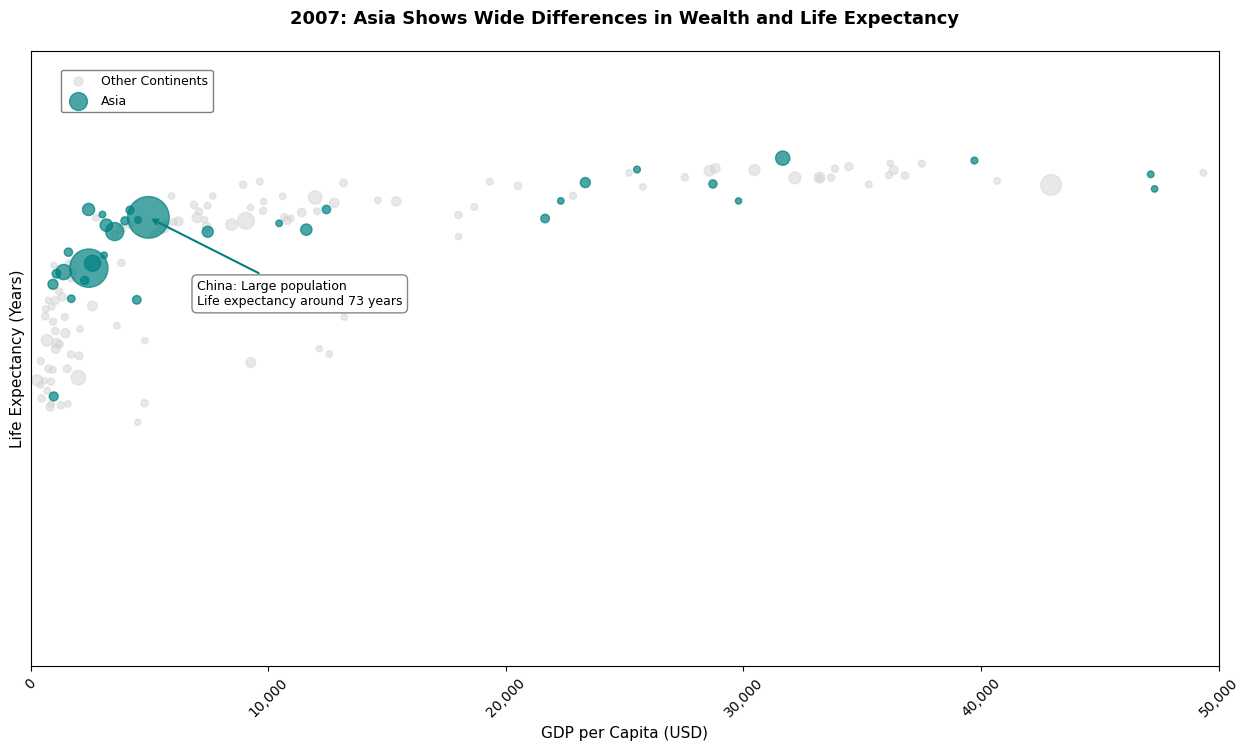

In [32]:
# Task 2: Bubble Chart

# Filter data for 2007
data_2007 = df[df["year"] == 2007].copy()

# Separate Asia and other continents
asia = data_2007[
    data_2007["continent"] == "Asia"
]

others = data_2007[
    data_2007["continent"] != "Asia"
]

# Bubble size based on population
size_max = 900
max_population = data_2007["pop"].max()

def bubble_size(population):
    return 20 + (
        population / max_population
    ) * (size_max - 20)

# Create figure
fig, ax = plt.subplots(figsize=(13, 8))

# Plot other continents in grey
ax.scatter(
    others["gdpPercap"],
    others["lifeExp"],
    s=bubble_size(others["pop"]),
    color="lightgray",
    alpha=0.5,
    label="Other Continents"
)

# Plot Asia in teal
ax.scatter(
    asia["gdpPercap"],
    asia["lifeExp"],
    s=bubble_size(asia["pop"]),
    color="teal",
    alpha=0.7,
    label="Asia"
)

# Highlight China
china = asia[asia["country"] == "China"].iloc[0]

ax.annotate(
    "China: Large population\nLife expectancy around 73 years",
    xy=(china["gdpPercap"], china["lifeExp"]),
    xytext=(35, -45),
    textcoords="offset points",
    fontsize=9,
    ha="left",
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="gray",
        alpha=0.95
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="teal",
        lw=1.5
    )
)

# X-axis: Linear scale starting at zero
ax.set_xscale("linear")
ax.set_xlim(0, 50000)

ax.set_xticks(
    np.arange(0, 50001, 10000)
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Y-axis: Starting at zero with gap of 5
ax.set_ylim(0, 100)

ax.set_yticks(
    np.arange(101, 40)
)

# Axis labels
ax.set_xlabel(
    "GDP per Capita (USD)",
    fontsize=11
)

ax.set_ylabel(
    "Life Expectancy (Years)",
    fontsize=11
)

# Chart title
ax.set_title(
    "2007: Asia Shows Wide Differences in Wealth and Life Expectancy",
    fontsize=13,
    fontweight="bold",
    pad=20
)

# Legend inside the plot
ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.02, 0.98),
    frameon=True,
    facecolor="white",
    edgecolor="gray",
    framealpha=1,
    fontsize=9,
    markerscale=0.6
)

# Remove all grid lines
ax.grid(False, which="both", axis="both")

# White background
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

# Improve spacing
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout(pad=2.5)

# Save PNG
fig.savefig(
    output_dir / "task2_bubble.png",
    dpi=300,
    bbox_inches="tight"
)

# Save PDF
fig.savefig(
    output_dir / "task2_bubble.pdf",
    bbox_inches="tight"
)

# Display figure
plt.show()
